Remove or transform extreme outliers by implementing multiple outlier-handling strategies, such as Winsorization and log transformations, and justify the chosen method with a comparative analysis.

In [1]:
import pandas as pd
import math
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("heart_disease_with_risk_factor.csv")

# Numerical columns
numerical_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   patient_id  age     sex                cp  trestbps  chol    fbs restecg  \
0           1   69    Male    Typical Angina       188   266  False  Normal   
1           2   56    Male    Typical Angina       105   237  False     LVH   
2           3   57  Female    Typical Angina       191   538  False     LVH   
3           4   34  Female    Typical Angina       139   559   True     LVH   
4           5   34  Female  Non-anginal Pain       167   224  False  Normal   

   thalach exang  oldpeak        slope     ca               thal  target  \
0      106    No      4.2  Downsloping   Zero  Reversible Defect       1   
1       77    No      4.4  Downsloping  Three             Normal       0   
2      179   Yes      1.7    Upsloping    Two             Normal       1   
3      138    No      4.5  Downsloping   Zero       Fixed Defect       0   
4      129   Yes      6.1    Upsloping   Zero       Fixed Defect       1   

   chol_percentile  thalach_percentile 

In [2]:
# Manual mean
def manual_mean(values):

    total = 0

    for value in values:
        total += value

    return total / len(values)


# Manual percentile
def manual_percentile(values, percentage):

    sorted_values = values.copy()

    for i in range(len(sorted_values)):

        for j in range(i + 1, len(sorted_values)):

            if sorted_values[i] > sorted_values[j]:

                sorted_values[i], sorted_values[j] = (
                    sorted_values[j],
                    sorted_values[i]
                )

    position = (
        (len(sorted_values) - 1)
        * percentage
    )

    lower = int(position)
    upper = lower + 1

    if upper >= len(sorted_values):

        return sorted_values[lower]

    fraction = position - lower

    return (
        sorted_values[lower]
        +
        fraction
        * (
            sorted_values[upper]
            - sorted_values[lower]
        )
    )


# Manual standard deviation
def manual_std(values):

    mean = manual_mean(values)

    total = 0

    for value in values:

        total += (
            value - mean
        ) ** 2

    variance = total / len(values)

    return math.sqrt(variance)

In [4]:
# Store transformed datasets
winsorized_df = df.copy()
log_df = df.copy()

# Convert numerical columns to float
for column in numerical_columns:

    winsorized_df[column] = (
        winsorized_df[column].astype(float)
    )

    log_df[column] = (
        log_df[column].astype(float)
    )
    
comparison = []


for column in numerical_columns:

    values = []

    for value in df[column]:

        if pd.notna(value):

            values.append(float(value))

    if len(values) == 0:
        continue

    # Calculate quartiles
    q1 = manual_percentile(
        values,
        0.25
    )

    q3 = manual_percentile(
        values,
        0.75
    )

    # Calculate IQR
    iqr = q3 - q1

    # Calculate IQR limits
    lower_limit = q1 - (
        1.5 * iqr
    )

    upper_limit = q3 + (
        1.5 * iqr
    )

    # Count original outliers
    original_outliers = 0

    for value in values:

        if (
            value < lower_limit
            or value > upper_limit
        ):

            original_outliers += 1

    # Apply Winsorization
    for i in range(len(df)):

        value = df[column].iloc[i]

        if pd.notna(value):

            value = float(value)

            if value < lower_limit:

                winsorized_df.loc[
                    i,
                    column
                ] = lower_limit

            elif value > upper_limit:

                winsorized_df.loc[
                    i,
                    column
                ] = upper_limit

            else:

                winsorized_df.loc[
                    i,
                    column
                ] = value

    # Apply log transformation
    for i in range(len(df)):

        value = df[column].iloc[i]

        if pd.notna(value):

            value = float(value)

            # log1p handles zero safely
            if value >= 0:

                log_df.loc[
                    i,
                    column
                ] = math.log1p(value)

            else:

                log_df.loc[
                    i,
                    column
                ] = value

    # Calculate statistics after Winsorization
    winsorized_values = []

    for value in winsorized_df[column]:

        if pd.notna(value):

            winsorized_values.append(
                float(value)
            )

    # Calculate statistics after log transformation
    log_values = []

    for value in log_df[column]:

        if pd.notna(value):

            log_values.append(
                float(value)
            )

    # Compare standard deviation
    original_std = manual_std(values)

    winsorized_std = manual_std(
        winsorized_values
    )

    log_std = manual_std(
        log_values
    )

    comparison.append({
        "Feature": column,
        "Original Outliers": original_outliers,
        "Original Std": round(
            original_std,
            3
        ),
        "Winsorized Std": round(
            winsorized_std,
            3
        ),
        "Log Std": round(
            log_std,
            3
        )
    })


# Create comparison table
comparison_df = pd.DataFrame(
    comparison
)

print("\nOutlier Handling Comparison")
print("=" * 70)

print(
    comparison_df.to_string(
        index=False
    )
)


Outlier Handling Comparison
 Feature  Original Outliers  Original Std  Winsorized Std  Log Std
     age                  0        14.034          14.034    0.276
trestbps                  0        31.728          31.728    0.222
    chol                  0       130.771         130.771    0.412
 thalach                  0        35.337          35.337    0.266
 oldpeak                  0         1.695           1.695    0.489


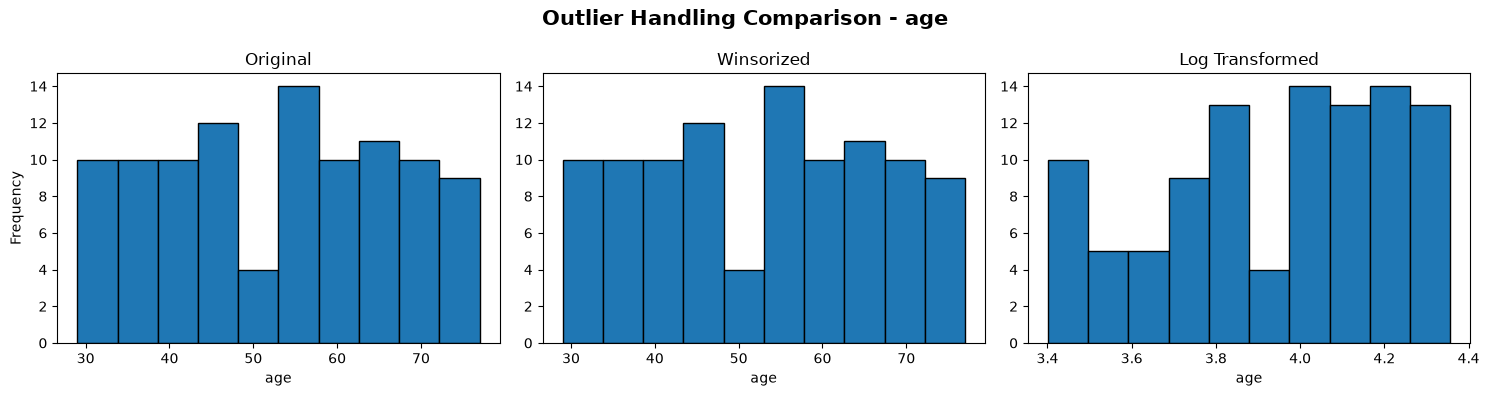

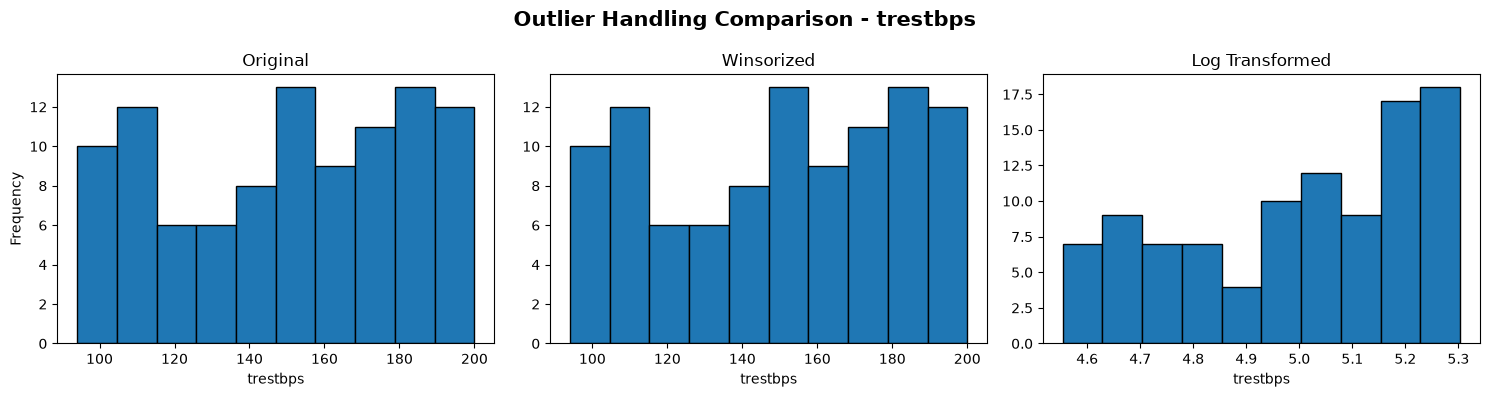

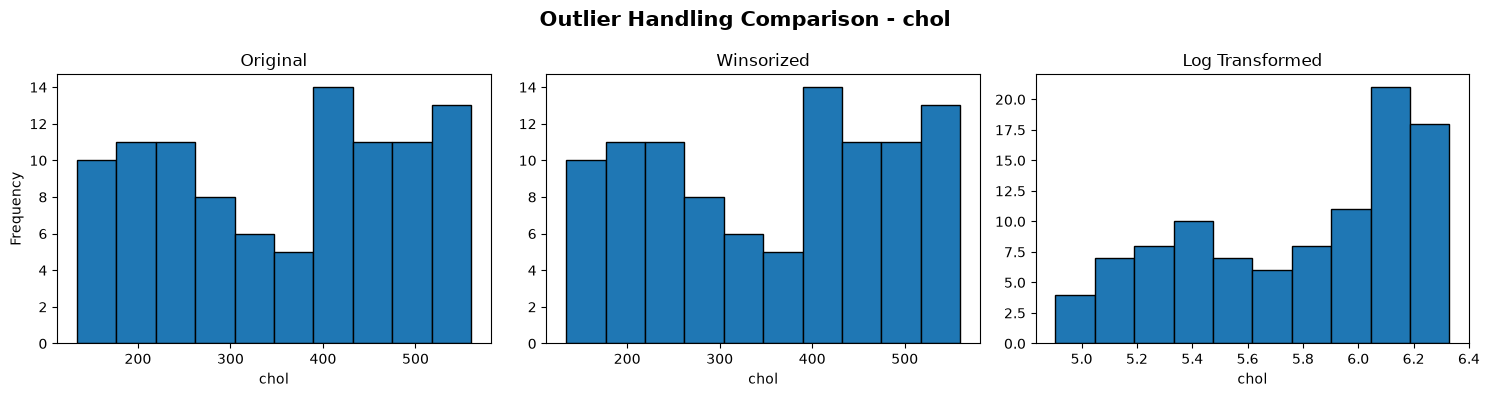

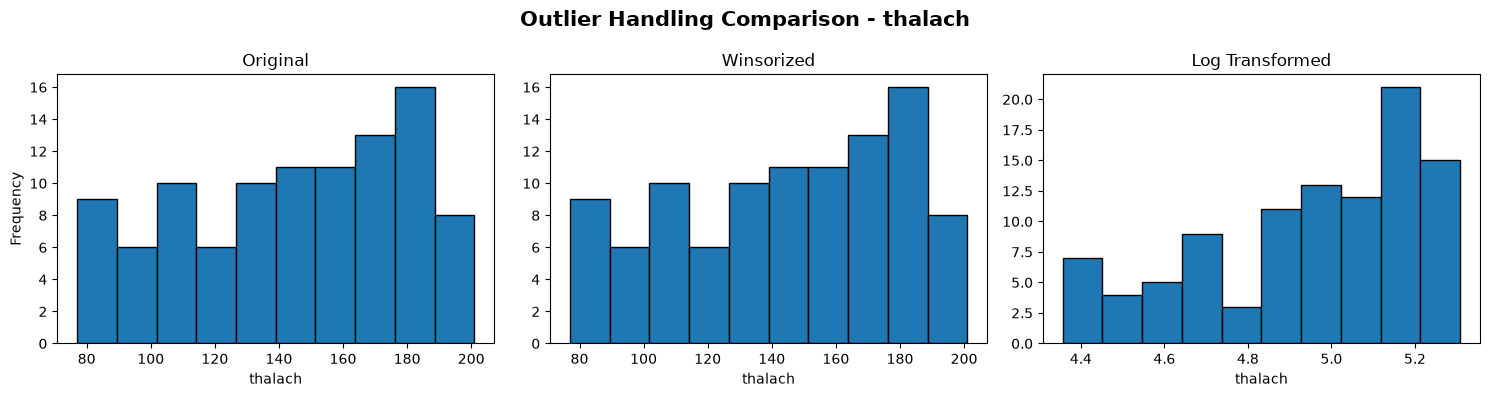

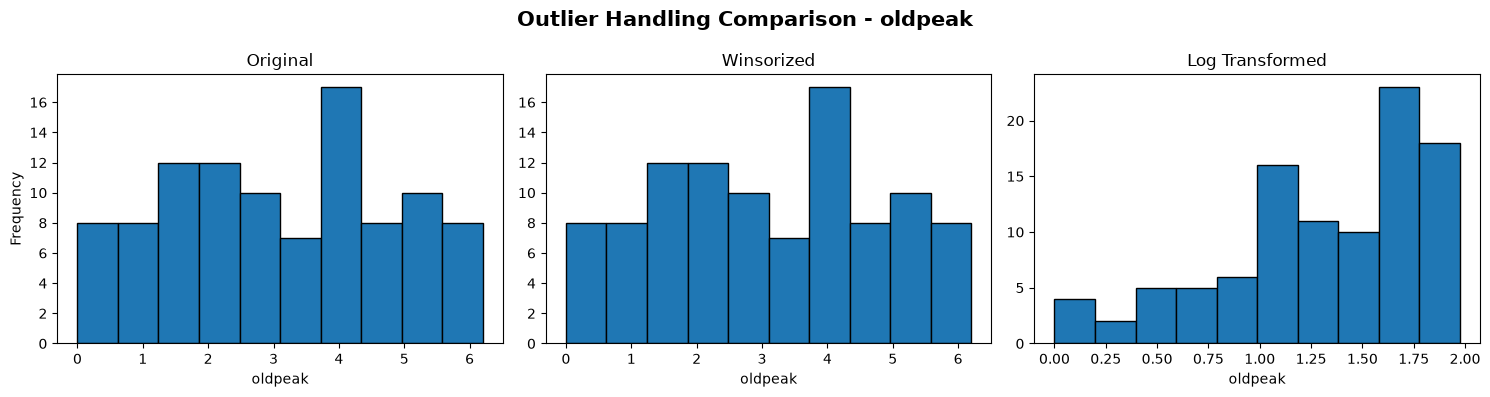

In [5]:
# Compare original, Winsorized and log transformed data

for column in numerical_columns:

    original_values = []
    winsorized_values = []
    log_values = []

    for value in df[column]:

        if pd.notna(value):
            original_values.append(
                float(value)
            )

    for value in winsorized_df[column]:

        if pd.notna(value):
            winsorized_values.append(
                float(value)
            )

    for value in log_df[column]:

        if pd.notna(value):
            log_values.append(
                float(value)
            )

    # Create three comparison plots
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 4)
    )

    axes[0].hist(
        original_values,
        bins=10,
        edgecolor="black"
    )

    axes[0].set_title(
        "Original"
    )

    axes[1].hist(
        winsorized_values,
        bins=10,
        edgecolor="black"
    )

    axes[1].set_title(
        "Winsorized"
    )

    axes[2].hist(
        log_values,
        bins=10,
        edgecolor="black"
    )

    axes[2].set_title(
        "Log Transformed"
    )

    axes[0].set_xlabel(column)
    axes[1].set_xlabel(column)
    axes[2].set_xlabel(column)

    axes[0].set_ylabel(
        "Frequency"
    )

    fig.suptitle(
        f"Outlier Handling Comparison - {column}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()